# R7-A2 - Brazo del agente de optimización: fase B (atenuación de los pesos de clase, α)

**Objetivo.** Describir AP(α) y ROC-AUC(α) en E2 con tres semillas, aplicando literalmente `results/classification/r7_optimizacion/agente/fase_b_alpha/protocolo_fase_b.json`, para ver si la mejora de B2 sobre B0 en E1 refleja un efecto de α o el ruido entre semillas y particiones. Es un estudio descriptivo: no hay regla de elección, p-valores ni intervalos de confianza, y no usa test. El «mejor α observado» es exploratorio y no entra a R8.

**Diseño.** ConvNeXt-Tiny, imagen completa, E2 (5 folds), semillas 42, 43 y 44; todo lo demás como B0. Solo cambia `--class-weight-alpha`.

| α | id | Corridas |
|---|---|---|
| 0.0, 0.25, 0.75 | `alpha_000`, `alpha_025`, `alpha_075` | 45 nuevas en `fase_b_alpha/corridas/` |
| 0.5 (B2) | `alpha_050` | 15 reutilizadas: semilla 42 de `robustez_e2`, 43 y 44 de `agente/confirmacion` |
| 1.0 (B0) | `alpha_100` | 15 reutilizadas, igual que B2 |

Si la huella de equivalencia (`verificacion_equivalencia/veredicto_huella.txt`) no se cumple, la semilla 42 de B0 y B2 sale de las 10 corridas condicionales del protocolo.

## 1. Configuración

In [1]:
from pathlib import Path
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.classification import agente_fase_b_analysis as fb  # toda la lógica del análisis está en este módulo

ANALYSIS_DIR = PROJECT_ROOT / fb.PHASE_B_REL / fb.ANALYSIS_NAME
OUTPUTS = {key: ANALYSIS_DIR / name for key, name in fb.OUTPUT_FILES.items()}
FIGURES = {key: ANALYSIS_DIR / name for key, name in fb.FIGURE_FILES.items()}

PROTOCOL, PROTOCOL_PATH = fb.load_protocol(PROJECT_ROOT)
DESIGN = fb.design(PROTOCOL)
ALPHAS, SEEDS, N_FOLDS = DESIGN["alphas"], DESIGN["seeds"], len(DESIGN["folds"])

FOLD_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9"]
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def require(condition, message):
    if not condition:
        raise AssertionError(message)


print(f"Protocolo: {PROTOCOL_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Estado declarado: {PROTOCOL['estado']}")
print(f"Rejilla de α: {ALPHAS} | semillas: {SEEDS} | folds: {N_FOLDS}")

Protocolo: results/classification/r7_optimizacion/agente/fase_b_alpha/protocolo_fase_b.json
Estado declarado: redactado el 2026-11-16 y aprobado con tres cambios por el autor; pendiente de commit del autor; ninguna corrida de la fase B ejecutada; huella de equivalencia aún no producida
Rejilla de α: [0.0, 0.25, 0.5, 0.75, 1.0] | semillas: [42, 43, 44] | folds: 5


## 2. Protocolo y comandos de entrenamiento

Las 45 corridas nuevas y su comando están escritos en el protocolo (`comandos.corridas`); las 10 condicionales solo se corren si la huella de equivalencia no se cumple o no se aporta. Con `RUN_TRAINING = False` no se inicia ningún entrenamiento. Con `True` (solo en Falcon, con el protocolo y la huella ya versionados) se lanzan las que falten, sin sobrescribir carpetas con archivos. Una corrida que falla por infraestructura se repite una vez con el mismo comando; si vuelve a fallar, se registra como descartada y su α se informa como incompleto.

In [2]:
RUN_TRAINING = False  # True para lanzar desde este notebook las corridas que falten (Falcon); False solo las lista

fingerprint_ok, _ = fb.fingerprint_accepted(PROJECT_ROOT, PROTOCOL)
planned = fb.planned_new_runs(PROTOCOL) + ([] if fingerprint_ok else fb.planned_conditional_runs(PROTOCOL))
done = [run["id"] for run in planned if (PROJECT_ROOT / run["dir_rel"] / "validation_metrics.json").exists()]
print(f"Huella de equivalencia: {fingerprint_ok} -> semilla 42 de B0 y B2: {'reutilizada' if fingerprint_ok else 'condicional (10 corridas)'}")
print(f"Corridas con resultados: {len(done)} de {len(planned)}")
print("Ejemplo de comando:\n" + planned[0]["command"])

if not RUN_TRAINING:
    print("\nRUN_TRAINING = False: no se inicia ningún entrenamiento.")
else:
    for run in planned:
        output_dir = PROJECT_ROOT / run["dir_rel"]
        print("=" * 80)
        print(f"{run['id']} -> {run['dir_rel']}/")
        if output_dir.exists() and any(output_dir.iterdir()):
            print("Omitida: la carpeta ya contiene archivos y no se sobrescribe. Si una corrida quedó incompleta, revísela o muévala manualmente.")
            continue
        process = subprocess.Popen([sys.executable, *shlex.split(run["command"])[1:]], cwd=PROJECT_ROOT,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1)
        try:
            for line in process.stdout:
                print(line, end="")
        except KeyboardInterrupt:
            process.terminate()  # al interrumpir la celda no debe quedar un entrenamiento huérfano
            raise
        if process.wait() != 0:
            raise RuntimeError(f"La corrida {run['id']} terminó con error (código {process.returncode}).")

Huella de equivalencia: True -> semilla 42 de B0 y B2: reutilizada
Corridas con resultados: 45 de 45
Ejemplo de comando:
python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_agente --seed 42 --checkpoint-metric val_roc_auc --class-weight-alpha 0.0 --split-csv configs/splits/cv_folds_e2.csv --fold 0 --output-dir results/classification/r7_optimizacion/agente/fase_b_alpha/corridas/alpha_000/seed_42/fold_0

RUN_TRAINING = False: no se inicia ningún entrenamiento.


## 3. Carga y verificación de las corridas

Esta sección solo lee archivos. Para cada corrida comprueba: `class_weight_alpha` registrado igual al del comando; pesos de clase recalculados con las etiquetas de train del fold; SHA-256 de `fold_manifest.csv` igual al de B0 en el mismo fold; claves de configuración iguales a B0; semilla y fold; sin NaN; época del checkpoint dentro del rango; y AP y ROC-AUC reproducibles. Con la reutilización, comprueba además que el piso de ruido y los pares de semillas del protocolo se reproducen. Si falta una corrida o falla una comprobación, no se escribe ningún resultado.

Las tablas se escriben en `fase_b_alpha/analisis/` mediante `src/classification/agente_fase_b_analysis.py`; si ya existen, solo se leen.

In [3]:
if not any(path.exists() for path in OUTPUTS.values()):
    exit_code, _ = fb.run_analysis(PROJECT_ROOT, verbose=False)
    require(exit_code == 0, "El análisis no se escribió: faltan corridas o hay comprobaciones fallidas (ejecute `python -m src.classification.agente_fase_b_analysis`).")
else:
    require(all(path.exists() for path in OUTPUTS.values()), "fase_b_alpha/analisis/ está incompleta; revise la carpeta antes de continuar.")

verification = pd.read_csv(OUTPUTS["verification"])
print(f"Comprobaciones: {len(verification)} | fallidas: {int((~verification['ok']).sum())}")
display(verification.groupby("comprobacion", sort=False)["ok"].agg(corridas="size", todas_ok="all"))

summary_json = json.loads(OUTPUTS["best_alpha"].read_text(encoding="utf-8"))
print(f"α incompletos: {summary_json['alphas_incompletos'] or 'ninguno'} | semilla 42 de B0 y B2: {summary_json['piso_de_ruido']['semilla_42']}")

Comprobaciones: 2826 | fallidas: 0


,corridas,todas_ok
comprobacion,,
"45 corridas nuevas = 3 α x 3 semillas x 5 folds, ids únicos",1,True
"cada comando nuevo = plantilla con su id, α, semilla y fold",1,True
orden por semilla (42 -> 43 -> 44),1,True
los α nuevos son los de la rejilla distintos de 1.0 y 0.5,1,True
"10 condicionales = B0 y B2, semilla 42, 5 folds, plantilla (B0 sin --class-weight-alpha)",1,True
...,...,...
valor del protocolo: B2_42_a_44,1,True
valor del protocolo: B2_43_a_44,1,True
valor del protocolo: piso_ap,1,True


α incompletos: ninguno | semilla 42 de B0 y B2: reutilizada


## 4. Curva AP(α) y ROC-AUC(α)

Por α: media de las 3 semillas por fold, media global (15 corridas), mínimo, máximo y DE entre semillas por fold. La forma se describe como monótona o no monótona, sin ajustar ningún modelo. Figura 1: media global (línea gruesa) y media por fold (líneas finas).

,ap_medio,ap_min_medias_por_fold,ap_max_medias_por_fold,ap_de_entre_semillas_media_folds,roc_auc_medio,roc_auc_min_medias_por_fold,roc_auc_max_medias_por_fold
alpha,,,,,,,
0.00,0.5769,0.4680,0.6441,0.0584,0.8826,0.8175,0.9327
0.25,0.5957,0.5274,0.6774,0.0538,0.8788,0.8270,0.9388
0.50,0.5663,0.4507,0.6734,0.0704,0.8764,0.8007,0.9227
0.75,0.5890,0.5313,0.6398,0.0590,0.8779,0.8482,0.8962
1.00,0.5910,0.5191,0.6789,0.0671,0.8914,0.8336,0.9293


Forma de la curva: {'ap': 'no_monotona', 'roc_auc': 'no_monotona', 'alphas_en_orden': [0.0, 0.25, 0.5, 0.75, 1.0], 'completa': True}


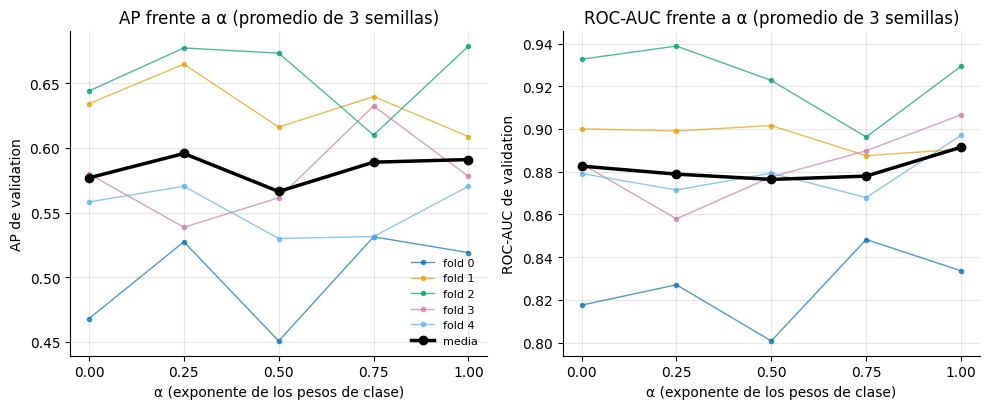

In [4]:
curve = pd.DataFrame(summary_json["curva"]).set_index("alpha")
display(curve[["ap_medio", "ap_min_medias_por_fold", "ap_max_medias_por_fold", "ap_de_entre_semillas_media_folds",
               "roc_auc_medio", "roc_auc_min_medias_por_fold", "roc_auc_max_medias_por_fold"]].round(4))
print(f"Forma de la curva: {summary_json['forma_de_la_curva']}")

by_fold = pd.read_csv(OUTPUTS["by_fold"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (column, title) in zip(axes, (("ap", "AP"), ("roc_auc", "ROC-AUC"))):
    for k in range(N_FOLDS):
        fold = by_fold[by_fold["fold"] == k].sort_values("alpha")
        ax.plot(fold["alpha"], fold[f"{column}_media_semillas"], color=FOLD_COLORS[k], linewidth=1, alpha=0.7, marker="o", markersize=3, label=f"fold {k}")
    ax.plot(curve.index, curve[f"{column}_medio"], color="black", linewidth=2.5, marker="o", label="media")
    ax.set_xticks(ALPHAS)
    ax.set_xlabel("α (exponente de los pesos de clase)")
    ax.set_ylabel(f"{title} de validation")
    ax.set_title(f"{title} frente a α (promedio de 3 semillas)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
if not FIGURES["fig1"].exists():  # no se sobrescribe
    fig.savefig(FIGURES["fig1"], dpi=150, bbox_inches="tight")
plt.show()

## 5. Δ frente a B0 (α = 1.0)

Δ = métrica(α) - métrica(B0) en el mismo fold y la misma semilla. Lectura a: por semilla. Lectura b (principal): promedio de las 3 semillas por fold, con la regla 4/5 en ambas direcciones. Lectura c: signos de los 15 pares (semilla, fold). ROC-AUC solo es descriptiva. Figura 2: ΔAP por fold y por α (lectura b).

,alpha,lectura,semillas,media,minimo,maximo,positivos,negativos,ceros,veredicto,etiqueta
0,0.00,a_por_semilla,42,-0.0117,-0.0963,0.1127,2,3,0,NaN,NaN
1,0.00,a_por_semilla,43,-0.0265,-0.1167,0.0774,2,3,0,NaN,NaN
2,0.00,a_por_semilla,44,-0.0042,-0.1002,0.0824,3,2,0,NaN,NaN
3,0.00,b_promedio_3_semillas,"42,43,44",-0.0141,-0.0511,0.0254,2,3,0,no_consistente,dentro_del_piso_de_ruido
4,0.00,c_15_pares,"42,43,44",NaN,NaN,NaN,7,8,0,NaN,NaN
10,0.25,a_por_semilla,42,-0.0132,-0.0756,0.1025,2,3,0,NaN,NaN
11,0.25,a_por_semilla,43,-0.0380,-0.1419,0.0623,2,3,0,NaN,NaN
12,0.25,a_por_semilla,44,0.0653,-0.0001,0.1782,4,1,0,NaN,NaN
13,0.25,b_promedio_3_semillas,"42,43,44",0.0047,-0.0394,0.0560,2,3,0,no_consistente,dentro_del_piso_de_ruido
14,0.25,c_15_pares,"42,43,44",NaN,NaN,NaN,8,7,0,NaN,NaN


,alpha,media,minimo,maximo,positivos,negativos
8,0.00,-0.0088,-0.0230,0.0095,2,3
18,0.25,-0.0126,-0.0487,0.0094,2,3
28,0.50,-0.0151,-0.0329,0.0111,1,4
38,0.75,-0.0135,-0.0331,0.0146,1,4


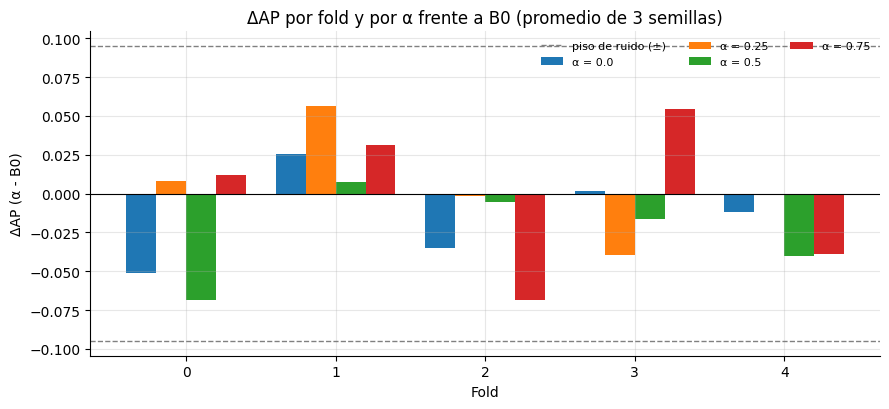

In [5]:
delta_summary = pd.read_csv(OUTPUTS["delta_summary"])
display(delta_summary[delta_summary["metrica"] == "AP"][["alpha", "lectura", "semillas", "media", "minimo", "maximo", "positivos", "negativos", "ceros", "veredicto", "etiqueta"]].round(4))
display(delta_summary[(delta_summary["metrica"] == "ROC-AUC") & (delta_summary["lectura"] == "b_promedio_3_semillas")][["alpha", "media", "minimo", "maximo", "positivos", "negativos"]].round(4))

deltas = pd.read_csv(OUTPUTS["delta"])
reading_b = deltas[deltas["metrica"] == "AP"].groupby(["alpha", "fold"])["delta"].mean().unstack("alpha")  # Δ pareado: media de las semillas = lectura b
piso = summary_json["piso_de_ruido"]["piso_ap"]

fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.8 / len(reading_b.columns)
for i, alpha in enumerate(reading_b.columns):
    ax.bar(reading_b.index + (i - (len(reading_b.columns) - 1) / 2) * width, reading_b[alpha], width=width, label=f"α = {alpha}")
ax.axhline(0, color="black", linewidth=0.8)
for sign in (1, -1):
    ax.axhline(sign * piso, color="gray", linestyle="--", linewidth=1, label="piso de ruido (±)" if sign == 1 else None)
ax.set_xticks(range(N_FOLDS))
ax.set_xlabel("Fold")
ax.set_ylabel("ΔAP (α - B0)")
ax.set_title("ΔAP por fold y por α frente a B0 (promedio de 3 semillas)")
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout()
if not FIGURES["fig2"].exists():  # no se sobrescribe
    fig.savefig(FIGURES["fig2"], dpi=150, bbox_inches="tight")
plt.show()

## 6. Piso de ruido y etiqueta de lectura

El piso es la mayor diferencia de AP medio entre dos semillas de una misma configuración (B0 o B2) en los mismos folds. Un α queda «por encima del piso» solo si la lectura b es consistente, el Δ medio tiene el mismo signo en las 3 semillas y |ΔAP medio| supera el piso; en cualquier otro caso queda «dentro del piso de ruido». Es un criterio descriptivo, no inferencial.

In [6]:
floor = pd.read_csv(OUTPUTS["noise_floor"])
pairs = floor[(floor["tipo"] == "par_de_semillas") & (floor["metrica"] == "AP")]
display(pairs[["configuracion", "semillas", "valor", "folds_positivos", "folds_negativos", "veredicto_4_de_5"]].round(4))
noise = summary_json["piso_de_ruido"]
print(f"Piso de AP: {noise['piso_ap']:.4f} ({noise['par_que_lo_define']}) | pares de una misma configuración que cumplen 4/5: "
      f"{noise['pares_de_una_misma_configuracion_que_cumplen_4_de_5']} de {noise['pares']}")
display(pd.DataFrame(summary_json["etiquetas_frente_a_b0"]).T)

,configuracion,semillas,valor,folds_positivos,folds_negativos,veredicto_4_de_5
0,B0,42->43,0.0686,3.0,2.0,no_consistente
2,B0,42->44,-0.0102,3.0,2.0,no_consistente
4,B0,43->44,-0.0788,1.0,4.0,peor_consistente
18,B2,42->43,0.0949,4.0,1.0,mejor_consistente
20,B2,42->44,0.0186,3.0,2.0,no_consistente
22,B2,43->44,-0.0763,1.0,4.0,peor_consistente


Piso de AP: 0.0949 (B2 42->43) | pares de una misma configuración que cumplen 4/5: 3 de 6


,i_lectura_b_consistente,ii_mismo_signo_en_cada_semilla,iii_abs_delta_medio_b_mayor_que_piso,etiqueta,direccion_4_de_5_coincide_con_el_signo_medio
0.0,False,True,False,dentro_del_piso_de_ruido,False
0.25,False,False,False,dentro_del_piso_de_ruido,False
0.5,True,True,False,dentro_del_piso_de_ruido,True
0.75,False,False,False,dentro_del_piso_de_ruido,False


## 7. Mejor α observado (exploratorio)

El α con mayor AP medio sobre 3 semillas × 5 folds; empate (diferencia con el máximo < 0.005): mayor ROC-AUC medio y luego el α más cercano a 1.0. Es exploratorio, no confirmado y no entra a R8. La multiplicidad se informa con el cálculo aproximado del protocolo.

In [7]:
best = summary_json["mejor_alpha_observado"]
print(f"Rótulo: {summary_json['rotulo_obligatorio']}")
print(f"Mejor α observado: {best['alpha']} | AP medio máximo: {best['ap_maximo']:.4f} | en empate: {best['en_empate']} | el desempate cambia el resultado: {best['el_desempate_cambia_el_resultado']}")
m = summary_json["multiplicidad"]
print(f"Multiplicidad: {m['comparaciones']} comparaciones frente a B0; P(al menos una cumple 4/5 por azar) ≈ {m['p_al_menos_una']:.2f} ({m['nota']})")

Rótulo: exploratorio; definido después de ver E1 y E2; no confirmado; sin datos independientes; no entra a R8
Mejor α observado: 1.0 | AP medio máximo: 0.5957 | en empate: [0.25, 1.0] | el desempate cambia el resultado: True
Multiplicidad: 4 comparaciones frente a B0; P(al menos una cumple 4/5 por azar) ≈ 0.56 (aproximación gruesa: los folds no son independientes)


## 8. Descriptivas de entrenamiento

α cambia la entrada del early stopping (la pérdida de validation se pondera con los pesos de α), así que se describen las épocas ejecutadas y la época elegida frente a α. No se comparan métricas que dependen del umbral 0.5.

In [8]:
display(curve[["epocas_ejecutadas_media", "epoca_elegida_media"]].round(2))

,epocas_ejecutadas_media,epoca_elegida_media
alpha,,
0.00,11.07,9.20
0.25,10.47,8.87
0.50,11.13,8.80
0.75,11.27,9.80
1.00,13.00,10.53


## 9. Limitaciones

- E2 es estratificada y no por paciente: puede sobreestimar; los cinco folds no son independientes y cada fold de validation tiene 21 o 22 positivas.
- E2 contiene las 200 imágenes de validation de E1 con las que se eligió B2, y la fase B se diseñó después de ver E1, E2 y la fase A.
- α cambia el early stopping (pérdida de validation ponderada con α); no se separa ese efecto del de la ponderación del entrenamiento.
- Multiplicidad: con 4 comparaciones frente a B0, P(al menos una cumple 4/5 por azar) ≈ 0.56 (aproximación gruesa).
- La huella de equivalencia que permite reutilizar la semilla 42 es en CPU, sin preentrenamiento ni AMP.
- El «mejor α observado» es el máximo de cinco estimaciones ruidosas: sesgo al alza; no se confirma ni entra a R8. Categorías 6 y 7 agrupadas en la clase positiva operacional. Test no interviene.

## 10. Interpretación de resultados

*Pendiente.* Esta sección se redacta solo después de ejecutar el notebook, con las cifras de los archivos de `fase_b_alpha/analisis/` y sin añadir reglas a las del protocolo.